## Setup

In [1]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from scipy import stats, signal
from scipy.optimize import minimize_scalar
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"
pd.set_option("display.float_format", lambda x: f"{x:.6f}")


## Config — set Paths

In [2]:
import os

# project root 
THESIS_DATA_ROOT = Path(os.environ.get("THESIS_DATA_ROOT", "./thesis_data")).resolve()
ROOT = THESIS_DATA_ROOT
ROOT.mkdir(parents=True, exist_ok=True)

INDICES_PATH = THESIS_DATA_ROOT / "Phase 3" / "full_period_US_phase3_20260602_014115" / "US_full_period_phase3_daily_indices.csv"
SUMMARY_PATH = THESIS_DATA_ROOT / "Phase 3" / "full_period_US_phase3_20260602_014115" / "US_full_period_phase3_summary.csv"        

## Load data

### Index 

In [3]:
import os
from pathlib import Path

# project root 
THESIS_DATA_ROOT = Path(os.environ.get("THESIS_DATA_ROOT", "./thesis_data")).resolve()
ROOT = THESIS_DATA_ROOT
ROOT.mkdir(parents=True, exist_ok=True)

#  Submission Ready root 
SUBMISSION_ROOT = Path(os.environ.get(
    "SUBMISSION_ROOT", str(Path.home() / "Desktop" / "PCRA Index Thesis")
)).resolve()


INDICES_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 3 - Index"
                 / "US_full_period_phase3_daily_indices.csv")
SUMMARY_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 3 - Index"
                 / "US_full_period_phase3_summary.csv")

STAGE_A_DIRS = [
    SUBMISSION_ROOT / "Actual Run Data" / "Phase 1 - Articles Kept vs Rejected"
    / "Stage A" / "Full Data",
]

StageB_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 1 - Articles Kept vs Rejected")


figdir = SUBMISSION_ROOT / "Visuals" / "Discriminant Validity"
figdir.mkdir(parents=True, exist_ok=True)

print(f"SUBMISSION_ROOT: {SUBMISSION_ROOT}  {'✓' if SUBMISSION_ROOT.exists() else '✗ NOT FOUND'}")
print(f"  Indices: {INDICES_PATH}  {'✓' if INDICES_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Summary: {SUMMARY_PATH}  {'✓' if SUMMARY_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Incremental Construction: {StageB_PATH}  {'✓' if SUMMARY_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Figures: {figdir}  {'✓ created/exists' if figdir.exists() else '✗ FAILED'}")


SUBMISSION_ROOT: /Users/adam/Desktop/PCRA Index Thesis  ✓
  Indices: /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 3 - Index/US_full_period_phase3_daily_indices.csv  ✓
  Summary: /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 3 - Index/US_full_period_phase3_summary.csv  ✓
  Incremental Construction: /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 1 - Articles Kept vs Rejected  ✓
  Figures: /Users/adam/Desktop/PCRA Index Thesis/Visuals/Discriminant Validity  ✓ created/exists


### Derived financial-data paths (EM-DAT, EPU, CPU)

In [4]:
from pathlib import Path


EMDAT_DIR = SUBMISSION_ROOT / "Financial Data" / "Disaster"
EPU_DIR   = SUBMISSION_ROOT / "Financial Data" / "Other Indices"

# Country name --> ISO code for EM-DAT filenames
EMDAT_FILES = {
    "US": EMDAT_DIR / "EMDAT_US.xlsx",
}

# Verify expected paths exist
print(f"SUBMISSION_ROOT: {SUBMISSION_ROOT}  {'✓' if SUBMISSION_ROOT.exists() else '✗ NOT FOUND'}")
print(f"  EM-DAT:    {EMDAT_DIR}  {'✓' if EMDAT_DIR.exists() else '✗ NOT FOUND'}")
print(f"  Other Idx: {EPU_DIR}  {'✓' if EPU_DIR.exists() else '✗ NOT FOUND'}")

SUBMISSION_ROOT: /Users/adam/Desktop/PCRA Index Thesis  ✓
  EM-DAT:    /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Disaster  ✓
  Other Idx: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Other Indices  ✓


#### EPU

In [5]:
#  Path 

EPU_PATH = EPU_DIR / "All_Daily_Policy_Data.csv"

print(f"  EPU path: {EPU_PATH}")
print(f"  Exists  : {'✓' if EPU_PATH.exists() else '✗ NOT FOUND'}")

if not EPU_PATH.exists():
    raise FileNotFoundError(
        f"EPU file not found at {EPU_PATH}\n"
        f"Files currently in Other Indices folder:\n"
        + "\n".join(f"  {f.name}" for f in EPU_DIR.iterdir())
        if EPU_DIR.exists() else
        f"EPU file not found at {EPU_PATH}\nOther Indices folder itself doesn't exist: {EPU_DIR}"
    )



epu_raw = pd.read_csv(EPU_PATH)
print(f"\n✓ Loaded EPU: {len(epu_raw):,} rows")
print(f"  Columns: {list(epu_raw.columns)}")

#  Build date from year month  day 

epu_raw["date"] = pd.to_datetime({
    "year":  epu_raw["year"].astype(int),
    "month": epu_raw["month"].astype(int),
    "day":   epu_raw["day"].astype(int),
}, errors="coerce")

# Clean & filter 

epu_df = epu_raw[["date", "daily_policy_index"]].copy()
epu_df.columns = ["date", "epu"]
epu_df["epu"] = pd.to_numeric(epu_df["epu"], errors="coerce")
epu_df = epu_df.dropna(subset=["date", "epu"])

epu_df = epu_df[
    (epu_df["date"] >= "2008-01-01") &
    (epu_df["date"] <= "2025-12-31")
].sort_values("date").reset_index(drop=True)

# Summary 

print(f"\n✓ epu_df ready")
print(f"  Observations : {len(epu_df):,}")
print(f"  Date range   : {epu_df['date'].min().date()} "
      f"→ {epu_df['date'].max().date()}")
print(f"  Mean EPU     : {epu_df['epu'].mean():.2f}")
print(f"  Max EPU      : {epu_df['epu'].max():.2f}")

display(epu_df.head())

  EPU path: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Other Indices/All_Daily_Policy_Data.csv
  Exists  : ✓

✓ Loaded EPU: 15,125 rows
  Columns: ['day', 'month', 'year', 'daily_policy_index']

✓ epu_df ready
  Observations : 6,575
  Date range   : 2008-01-01 → 2025-12-31
  Mean EPU     : 144.66
  Max EPU      : 1026.38


,date,epu
0,2008-01-01,232.870000
1,2008-01-02,83.140000
2,2008-01-03,189.340000
3,2008-01-04,103.240000
4,2008-01-05,281.750000


#### EMDAT

In [6]:
#  Load US EM-DAT file 

emdat_raw = pd.read_excel(EMDAT_FILES["US"])
print(f"\n✓ Loaded EM-DAT US: {len(emdat_raw):,} rows")
print(f"  Columns: {list(emdat_raw.columns)}")

#  Identify date column 

if "Start Year" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime({
        "year":  emdat_raw["Start Year"].fillna(0).astype(int),
        "month": emdat_raw["Start Month"].fillna(1).astype(int),
        "day":   emdat_raw["Start Day"].fillna(1).astype(int),
    }, errors="coerce")
elif "Disaster Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Disaster Date"], errors="coerce")
elif "Event Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Event Date"], errors="coerce")
else:
    raise RuntimeError(
        f"Cannot find a date column in EM-DAT. "
        f"Available columns: {list(emdat_raw.columns)}")

#  Filter to sample period & drop undated rows 

emdat_us = emdat_raw.dropna(subset=["event_date"]).copy()
emdat_us = emdat_us[
    (emdat_us["event_date"] >= "2008-01-01") &
    (emdat_us["event_date"] <= "2025-12-31")
].reset_index(drop=True)

print(f"  After date filter (2008–2025): {len(emdat_us):,} events")


✓ Loaded EM-DAT US: 417 rows
  Columns: ['DisNo.', 'Historic', 'Classification Key', 'Disaster Group', 'Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 'External IDs', 'Event Name', 'ISO', 'Country', 'Subregion', 'Region', 'Location', 'Origin', 'Associated Types', 'OFDA/BHA Response', 'Appeal', 'Declaration', "AID Contribution ('000 US$)", 'Magnitude', 'Magnitude Scale', 'Latitude', 'Longitude', 'River Basin', 'Start Year', 'Start Month', 'Start Day', 'End Year', 'End Month', 'End Day', 'Total Deaths', 'No. Injured', 'No. Affected', 'No. Homeless', 'Total Affected', "Reconstruction Costs ('000 US$)", "Reconstruction Costs, Adjusted ('000 US$)", "Insured Damage ('000 US$)", "Insured Damage, Adjusted ('000 US$)", "Total Damage ('000 US$)", "Total Damage, Adjusted ('000 US$)", 'CPI', 'Admin Units', 'GADM Admin Units', 'Entry Date', 'Last Update']
  After date filter (2008–2025): 417 events


#### CPU

In [7]:
# Path 
CPU_PATH = EPU_DIR / "cpu_pu.xlsx"
print(f"  CPU path: {CPU_PATH}")
print(f"  Exists  : {'✓' if CPU_PATH.exists() else '✗ NOT FOUND'}")

if not CPU_PATH.exists():
    raise FileNotFoundError(
        f"CPU file not found at {CPU_PATH}\n"
        f"Files currently in Other Indices folder:\n"
        + ("\n".join(f"  {f.name}" for f in EPU_DIR.iterdir())
           if EPU_DIR.exists() else f"  (folder itself doesn't exist: {EPU_DIR})"))


xl = pd.ExcelFile(CPU_PATH)
print(f"\n  Sheets available: {xl.sheet_names}")

#  Load sheet 2 data
cpu_raw = pd.read_excel(
    CPU_PATH,
    sheet_name=xl.sheet_names[1],
    dtype={"date": str})

print(f"\n✓ Loaded CPU from sheet: '{xl.sheet_names[1]}'")
print(f"  Rows              : {len(cpu_raw):,}")
print(f"  Columns           : {list(cpu_raw.columns)}")
print(f"  Date sample (raw) : {cpu_raw['date'].head(5).tolist()}")
display(cpu_raw.head(5))


cpu_raw["date"] = pd.to_datetime(
    cpu_raw["date"].astype(str).str.strip().str.replace("M", "-") + "-01",
    format="%Y-%m-%d",
    errors="coerce"
)
print(f"\n  Date sample (parsed): {cpu_raw['date'].dropna().head(3).tolist()}")

# Select index columns
cpu_value_cols = [c for c in cpu_raw.columns if c not in
                  ["year", "month", "day", "date"]]
print(f"  CPU value columns found: {cpu_value_cols}")

cpu_df = cpu_raw[["date"] + cpu_value_cols].copy()

# Standardise column names 
rename_map = {}
for col in cpu_value_cols:
    col_lower = col.lower()
    if "narrow" in col_lower and "news" not in col_lower:
        rename_map[col] = "cpu_index_narrow"
    elif "broad" in col_lower and "news" not in col_lower:
        rename_map[col] = "cpu_index_broad"
    elif "gavriilidis" in col_lower or col_lower in ["cpu", "cpu_index"]:
        rename_map[col] = "cpu_index_gavriilidis"
    elif "news" in col_lower and "narrow" in col_lower:
        rename_map[col] = "cpnews_index_narrow"
    elif "news" in col_lower and "broad" in col_lower:
        rename_map[col] = "cpnews_index_broad"
    elif "sent" in col_lower:
        rename_map[col] = "cpsent_index"
    elif "instrument" in col_lower:
        rename_map[col] = "cpu_instrument"
    elif "shock" in col_lower:
        rename_map[col] = "cpu_shock"

if rename_map:
    cpu_df = cpu_df.rename(columns=rename_map)
    print(f"  Renamed columns: {rename_map}")

#  Convert value columns to numeric 
for col in cpu_df.columns:
    if col != "date":
        cpu_df[col] = pd.to_numeric(cpu_df[col], errors="coerce")

cpu_df = (cpu_df
    .dropna(subset=["date"])
    .loc[lambda d: (d["date"] >= "2008-01-01") & (d["date"] <= "2025-12-31")]
    .sort_values("date")
    .reset_index(drop=True))

# Summary 
print(f"\n✓ cpu_df ready")
print(f"  Observations : {len(cpu_df):,}")
print(f"  Date range   : {cpu_df['date'].min().date()} "
      f"→ {cpu_df['date'].max().date()}")
print(f"  Columns      : {list(cpu_df.columns)}")
for col in cpu_df.columns:
    if col != "date":
        non_null = cpu_df[col].dropna()
        if len(non_null) > 0:
            print(f"  {col:<30s} mean={non_null.mean():.2f}  "
                  f"max={non_null.max():.2f}  "
                  f"n={len(non_null):,}")
        else:
            print(f"  {col:<30s} all NaN")
display(cpu_df.head())

  CPU path: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Other Indices/cpu_pu.xlsx
  Exists  : ✓

  Sheets available: ['readme', 'data']

✓ Loaded CPU from sheet: 'data'
  Rows              : 492
  Columns           : ['date', 'cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
  Date sample (raw) : ['1985M01', '1985M02', '1985M03', '1985M04', '1985M05']


,date,cpu_index_narrow,cpu_index_broad,cpu_index_gavriilidis,cpnews_index_narrow,cpnews_index_broad,cpsent_index,cpu_instrument,cpu_shock
0,1985M01,35.469868,67.558322,NaN,52.560527,54.654046,146.698243,NaN,NaN
1,1985M02,12.957033,16.960149,NaN,51.736757,51.679215,98.249098,NaN,NaN
2,1985M03,35.618421,61.085415,NaN,60.033463,58.400578,229.254864,NaN,NaN
3,1985M04,59.485346,48.462095,NaN,47.960487,51.492845,178.405419,NaN,NaN
4,1985M05,26.375457,34.621114,NaN,46.887293,49.883908,90.879046,NaN,NaN



  Date sample (parsed): [Timestamp('1985-01-01 00:00:00'), Timestamp('1985-02-01 00:00:00'), Timestamp('1985-03-01 00:00:00')]
  CPU value columns found: ['cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
  Renamed columns: {'cpu_index_narrow': 'cpu_index_narrow', 'cpu_index_broad': 'cpu_index_broad', 'cpu_index_gavriilidis': 'cpu_index_gavriilidis', 'cpnews_index_narrow': 'cpnews_index_narrow', 'cpnews_index_broad': 'cpnews_index_broad', 'cpsent_index': 'cpsent_index', 'cpu_instrument': 'cpu_instrument', 'cpu_shock': 'cpu_shock'}

✓ cpu_df ready
  Observations : 216
  Date range   : 2008-01-01 → 2025-12-01
  Columns      : ['date', 'cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
  cpu_index_narrow               mean=258.70  max=916.28  n=216
  cpu_index_broad               

,date,cpu_index_narrow,cpu_index_broad,cpu_index_gavriilidis,cpnews_index_narrow,cpnews_index_broad,cpsent_index,cpu_instrument,cpu_shock
0,2008-01-01,165.633687,139.253340,94.648509,142.021777,116.369936,95.839287,0.000000,0.325613
1,2008-02-01,143.749401,122.719308,96.943516,115.694766,104.871164,108.800735,0.000000,0.219075
2,2008-03-01,111.876447,75.812874,55.128163,129.749332,106.656863,168.340079,0.000000,-0.571754
3,2008-04-01,143.723709,125.556904,93.901780,149.634044,129.335019,183.769227,0.000000,0.479395
4,2008-05-01,153.042190,127.720523,85.667217,140.454251,128.767182,130.668079,-0.274189,0.681724


## Helpers

In [8]:
@dataclass
class CheckResult:
    name: str
    passed: bool | None
    value: str
    note: str = ""

    def show(self):
        if self.passed is None:
            tag = "[ INFO ]"
        elif self.passed:
            tag = "[ PASS ]"
        else:
            tag = "[ FAIL ]"
        print(f"{tag}  {self.name:55s}  {self.value}")
        if self.note:
            print(f"          note: {self.note}")


def ewma(x: np.ndarray, lam: float, init: float | None = None) -> np.ndarray:
    #SSI_t = lam*SSI_{t-1} + (1-lam)*S_t (proposal Phase 3)
    out = np.empty_like(x, dtype=float)
    out[0] = init if init is not None else x[0]
    for i in range(1, len(x)):
        out[i] = lam * out[i - 1] + (1.0 - lam) * x[i]
    return out


def kpss_safe(series, regression="c"):
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        stat, p, *_ = kpss(series, regression=regression, nlags="auto")
    return stat, p


def hl_to_lambda(hl: int) -> float:
    #Half-life (business days) -> EWMA lambda. lambda^h = 1/2
    return float(2.0 ** (-1.0 / hl))


def distance_correlation(x: np.ndarray, y: np.ndarray) -> float:
    #Szekely-Rizzo-Bakirov distance correlation. O(n^2)
    x = np.asarray(x, dtype=float).reshape(-1)
    y = np.asarray(y, dtype=float).reshape(-1)
    a = np.abs(x[:, None] - x[None, :])
    b = np.abs(y[:, None] - y[None, :])
    A = a - a.mean(0) - a.mean(1)[:, None] + a.mean()
    B = b - b.mean(0) - b.mean(1)[:, None] + b.mean()
    dcov2 = (A * B).mean()
    dvar_x = (A * A).mean()
    dvar_y = (B * B).mean()
    if dvar_x <= 0 or dvar_y <= 0:
        return 0.0
    return float(np.sqrt(max(dcov2, 0.0)) / np.sqrt(np.sqrt(dvar_x * dvar_y)))

results: list[CheckResult] = []

In [9]:
def ewma(x, lam, init=None):
    out = np.empty_like(x, dtype=float)
    out[0] = init if init is not None else x[0]
    for i in range(1, len(x)):
        out[i] = lam * out[i - 1] + (1.0 - lam) * x[i]
    return out


def kpss_safe(series, regression="c"):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        stat, p, *_ = kpss(series, regression=regression, nlags="auto")
    return stat, p


def variance_ratio(x, q):
    #Lo-MacKinlay variance ratio test. VR(q) and asymptotic z-stat
    n = len(x)
    mu = (x[-1] - x[0]) / n
    # sigma_1^2
    s1 = np.sum((x[1:] - x[:-1] - mu) ** 2) / (n - 1)
    # sigma_q^2
    diffs_q = x[q:] - x[:-q] - q * mu
    sq = np.sum(diffs_q ** 2) / (n - q)
    vr = sq / (q * s1) if s1 > 0 else np.nan
    # Asymptotic z under homoscedasticity
    z = (vr - 1) / np.sqrt(2 * (q - 1) / (3 * q * n)) if not np.isnan(vr) else np.nan
    return float(vr), float(z)

# Discriminant Validity

## Data Perparation

In [10]:
#Load CPU shock and instrument if available 
if "cpu_instrument" in cpu_df.columns:
    print("  cpu_instrument found")
if "cpu_shock" in cpu_df.columns:
    print("  cpu_shock found")

cpu_shock_cols = [c for c in ["cpu_instrument", "cpu_shock", "cpsent_index"]
                  if c in cpu_df.columns]
print(f"  CPU shock/instrument cols available: {cpu_shock_cols}")

  cpu_instrument found
  cpu_shock found
  CPU shock/instrument cols available: ['cpu_instrument', 'cpu_shock', 'cpsent_index']


### Load and align data to same Frequencies

In [11]:
#  Load combined daily indices 
df = pd.read_csv(INDICES_PATH)
df["date"] = pd.to_datetime(df["date"])

print(f"  Loaded : {len(df):,} rows")
print(f"  Columns: {list(df.columns)}")
print(f"  Range  : {df['date'].min().date()} → {df['date'].max().date()}")

df = df.rename(columns={"DSP": "CSP"})

  Loaded : 4,697 rows
  Columns: ['date', 'country', 'S_daily_raw', 'S_daily', 'SSI', 'DSP']
  Range  : 2008-01-01 → 2025-12-31


In [12]:
#  Monthly CSP aggregation 
csp_monthly = (df[["date", "CSP", "SSI"]]
    .copy()
    .assign(date=lambda d: pd.to_datetime(d["date"]))
    .assign(month=lambda d: d["date"].dt.to_period("M"))
    .groupby("month")
    .agg(
        CSP_mean    = ("CSP", "mean"),
        CSP_std     = ("CSP", "std"),
        CSP_max_abs = ("CSP", lambda x: x.abs().max()),
        CSP_n       = ("CSP", "count"),
    )
    .reset_index()
    .assign(date=lambda d: d["month"].dt.to_timestamp()))

print(f"Monthly CSP obs : {len(csp_monthly):,}")
print(f"Date range      : {csp_monthly['date'].min()} → {csp_monthly['date'].max()}")


Monthly CSP obs : 216
Date range      : 2008-01-01 00:00:00 → 2025-12-01 00:00:00


In [13]:
print(f"\nCPU columns: {cpu_df.columns.tolist()}")

print(f"EPU columns: {epu_df.columns.tolist()}")


CPU columns: ['date', 'cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
EPU columns: ['date', 'epu']


In [14]:
cpu_monthly = cpu_df.copy()
cpu_monthly["date"] = pd.to_datetime(
    cpu_monthly["date"]).dt.to_period("M").dt.to_timestamp()
cpu_monthly = (cpu_monthly
    .groupby("date")
    .mean(numeric_only=True)
    .reset_index())

epu_monthly = epu_df.copy()
epu_monthly["date"] = pd.to_datetime(
    epu_monthly["date"]).dt.to_period("M").dt.to_timestamp()
epu_monthly = (epu_monthly
    .groupby("date")
    .mean(numeric_only=True)
    .reset_index()
    .rename(columns={"epu": "EPU"}))

h_df = (csp_monthly
    .merge(cpu_monthly, on="date", how="left")
    .merge(epu_monthly, on="date", how="left"))

print(f"\nMerged monthly obs : {len(h_df):,}")
print(f"Columns            : {list(h_df.columns)}")
h_df.head()


Merged monthly obs : 216
Columns            : ['month', 'CSP_mean', 'CSP_std', 'CSP_max_abs', 'CSP_n', 'date', 'cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock', 'EPU']


,month,CSP_mean,CSP_std,CSP_max_abs,CSP_n,date,cpu_index_narrow,cpu_index_broad,cpu_index_gavriilidis,cpnews_index_narrow,cpnews_index_broad,cpsent_index,cpu_instrument,cpu_shock,EPU
0,2008-01,NaN,NaN,NaN,0,2008-01-01,165.633687,139.253340,94.648509,142.021777,116.369936,95.839287,0.000000,0.325613,182.061290
1,2008-02,NaN,NaN,NaN,0,2008-02-01,143.749401,122.719308,96.943516,115.694766,104.871164,108.800735,0.000000,0.219075,118.067241
2,2008-03,NaN,NaN,NaN,0,2008-03-01,111.876447,75.812874,55.128163,129.749332,106.656863,168.340079,0.000000,-0.571754,121.869032
3,2008-04,NaN,NaN,NaN,0,2008-04-01,143.723709,125.556904,93.901780,149.634044,129.335019,183.769227,0.000000,0.479395,100.466000
4,2008-05,NaN,NaN,NaN,0,2008-05-01,153.042190,127.720523,85.667217,140.454251,128.767182,130.668079,-0.274189,0.681724,84.734194


## Correlation Analysis

### Summary Statistics

In [15]:
stat_cols = [
    "CSP_mean", "CSP_std", "CSP_max_abs",
    "cpu_index_narrow", "cpu_index_broad", "cpu_index_gavriilidis",
    "cpnews_index_narrow", "cpnews_index_broad", "EPU",
]
stat_cols = [c for c in stat_cols if c in h_df.columns]

rows = []
for col in stat_cols:
    s = h_df[col].dropna()
    rows.append({
        "variable": col,
        "n":        len(s),
        "mean":     round(s.mean(), 4),
        "std":      round(s.std(), 4),
        "min":      round(s.min(), 4),
        "max":      round(s.max(), 4),
        "skew":     round(s.skew(), 4),
        "ex_kurtosis": round(s.kurt(), 4),
        "rho_1":    round(s.autocorr(1), 4),
    })

h_summary = pd.DataFrame(rows)
print("── Summary statistics ──")
display(h_summary)

── Summary statistics ──


,variable,n,mean,std,min,max,skew,ex_kurtosis,rho_1
0,CSP_mean,205,-0.002300,0.213300,-0.554200,0.687400,0.708800,0.799500,-0.031700
1,CSP_std,205,0.787100,0.617300,0.011100,3.199900,1.676400,3.297800,0.062000
2,CSP_max_abs,205,2.787900,2.705800,0.074700,14.542500,2.153900,5.283500,-0.021000
3,cpu_index_narrow,216,258.695900,173.232300,34.891300,916.281500,1.533800,2.326800,0.779600
4,cpu_index_broad,216,198.981100,107.277900,64.796700,618.489100,1.383900,1.623200,0.784400
5,cpu_index_gavriilidis,213,161.367000,96.890600,38.092100,593.266400,1.848400,4.397700,0.816100
6,cpnews_index_narrow,216,200.014500,79.244800,87.295400,477.638100,0.978300,0.551500,0.858300
7,cpnews_index_broad,216,148.944200,41.292900,88.940700,278.375000,0.952300,0.122300,0.872500
8,EPU,216,144.571300,90.394900,50.289300,560.876000,2.318700,6.232100,0.883100


### Pairwise Correlations

In [16]:
from scipy.stats import spearmanr, pearsonr

cpu_cols = [c for c in [
    "cpu_index_narrow", "cpu_index_broad", "cpu_index_gavriilidis",
    "cpnews_index_narrow", "cpnews_index_broad", "EPU",
] if c in h_df.columns]

corr_rows = []
for col in cpu_cols:
    tmp = h_df[["CSP_mean", col]].dropna()

    spearman_r, spearman_p = spearmanr(tmp["CSP_mean"], tmp[col])
    pearson_r, pearson_p   = pearsonr(tmp["CSP_mean"], tmp[col])

    corr_rows.append({
        "comparison":     f"CSP_mean vs {col}",
        "n":              len(tmp),
        "pearson_r":      round(pearson_r, 4),
        "pearson_p":      round(pearson_p, 4),
        "spearman_r":     round(spearman_r, 4),
        "spearman_p":     round(spearman_p, 4),
        "interpretation": "Negative association" if pearson_r < 0 else "Positive association",
    })

h_corr = pd.DataFrame(corr_rows)
print("── Pairwise correlations: CSP_mean vs CPU variants ──")
display(h_corr)

── Pairwise correlations: CSP_mean vs CPU variants ──


,comparison,n,pearson_r,pearson_p,spearman_r,spearman_p,interpretation
0,CSP_mean vs cpu_index_narrow,205,-0.104000,0.137900,-0.051400,0.464000,Negative association
1,CSP_mean vs cpu_index_broad,205,-0.086600,0.217100,-0.015300,0.827200,Negative association
2,CSP_mean vs cpu_index_gavriilidis,202,-0.063900,0.366300,-0.036300,0.608500,Negative association
3,CSP_mean vs cpnews_index_narrow,205,-0.081100,0.247800,-0.029400,0.675400,Negative association
4,CSP_mean vs cpnews_index_broad,205,-0.063400,0.366100,-0.020600,0.769300,Negative association
5,CSP_mean vs EPU,205,-0.002600,0.970500,-0.016700,0.812200,Negative association


### Full Correlation Matrix

In [17]:
matrix_cols = [c for c in [
    "CSP_mean", "CSP_max_abs",
    "cpu_index_narrow", "cpu_index_broad", "cpu_index_gavriilidis",
    "cpnews_index_narrow", "cpnews_index_broad", "EPU",
] if c in h_df.columns]

h_corr_matrix = h_df[matrix_cols].corr().round(3)
print("── Full correlation matrix ──")
display(h_corr_matrix)

── Full correlation matrix ──


,CSP_mean,CSP_max_abs,cpu_index_narrow,cpu_index_broad,cpu_index_gavriilidis,cpnews_index_narrow,cpnews_index_broad,EPU
CSP_mean,1.000000,0.701000,-0.104000,-0.087000,-0.064000,-0.081000,-0.063000,-0.003000
CSP_max_abs,0.701000,1.000000,-0.055000,-0.058000,-0.061000,-0.041000,-0.041000,-0.040000
cpu_index_narrow,-0.104000,-0.055000,1.000000,0.966000,0.891000,0.830000,0.803000,0.509000
cpu_index_broad,-0.087000,-0.058000,0.966000,1.000000,0.913000,0.813000,0.814000,0.535000
cpu_index_gavriilidis,-0.064000,-0.061000,0.891000,0.913000,1.000000,0.743000,0.733000,0.606000
cpnews_index_narrow,-0.081000,-0.041000,0.830000,0.813000,0.743000,1.000000,0.972000,0.262000
cpnews_index_broad,-0.063000,-0.041000,0.803000,0.814000,0.733000,0.972000,1.000000,0.233000
EPU,-0.003000,-0.040000,0.509000,0.535000,0.606000,0.262000,0.233000,1.000000


### Extended correlation table

In [18]:
from scipy.stats import pearsonr

extended_cols = [c for c in [
    "cpu_index_narrow",
    "cpu_index_broad",
    "cpu_index_gavriilidis",
    "cpnews_index_narrow",
    "cpnews_index_broad",
    "cpsent_index",
    "cpu_instrument",
    "cpu_shock",
] if c in h_df.columns]

ext_corr_rows = []
for col in extended_cols:
    tmp = h_df[["CSP_mean", col]].dropna()
    if len(tmp) < 10:
        continue
    pr,  pp  = spearmanr(tmp["CSP_mean"], tmp[col])
    r,   p   = pearsonr(tmp["CSP_mean"],  tmp[col])
    ext_corr_rows.append({
        "comparison":     f"CSP_mean vs {col}",
        "n":              len(tmp),
        "pearson_r":      round(r,  4),
        "pearson_p":      round(p,  4),
        "spearman_r":     round(pr, 4),
        "spearman_p":     round(pp, 4),
        "interpretation": "Negative association" if r < 0 else "Positive association",
    })

ext_corr_df = pd.DataFrame(ext_corr_rows)
print("── Extended pairwise correlations: CSP_mean vs all CPU variants ──")
display(ext_corr_df)

── Extended pairwise correlations: CSP_mean vs all CPU variants ──


,comparison,n,pearson_r,pearson_p,spearman_r,spearman_p,interpretation
0,CSP_mean vs cpu_index_narrow,205,-0.104000,0.137900,-0.051400,0.464000,Negative association
1,CSP_mean vs cpu_index_broad,205,-0.086600,0.217100,-0.015300,0.827200,Negative association
2,CSP_mean vs cpu_index_gavriilidis,202,-0.063900,0.366300,-0.036300,0.608500,Negative association
3,CSP_mean vs cpnews_index_narrow,205,-0.081100,0.247800,-0.029400,0.675400,Negative association
4,CSP_mean vs cpnews_index_broad,205,-0.063400,0.366100,-0.020600,0.769300,Negative association
5,CSP_mean vs cpsent_index,145,-0.023100,0.782700,0.003700,0.965200,Negative association
6,CSP_mean vs cpu_instrument,133,-0.076800,0.379300,-0.073000,0.403400,Negative association
7,CSP_mean vs cpu_shock,133,0.011900,0.891900,-0.015000,0.863900,Positive association


## Dynamic & Event-Based Ralationships

### Shock overlap analysis

In [19]:
cpu_col = "cpu_index_narrow"
shock_df = h_df[["date", "CSP_mean", "CSP_max_abs", cpu_col]].dropna().copy()

csp_threshold = float(shock_df["CSP_max_abs"].quantile(0.75))
cpu_threshold = float(shock_df[cpu_col].quantile(0.75))

shock_df["high_CSP"] = shock_df["CSP_max_abs"] >= csp_threshold
shock_df["high_CPU"] = shock_df[cpu_col]       >= cpu_threshold
shock_df["overlap"]  = shock_df["high_CSP"] & shock_df["high_CPU"]

n_high_csp = shock_df["high_CSP"].sum()
n_high_cpu = shock_df["high_CPU"].sum()
n_overlap  = shock_df["overlap"].sum()
overlap_rate = n_overlap / n_high_csp if n_high_csp > 0 else 0

overlap_table = pd.DataFrame([
    {"metric": "CSP shock threshold, top 25%",       "value": round(csp_threshold, 6)},
    {"metric": "CPU threshold, top 25%",              "value": round(cpu_threshold, 6)},
    {"metric": "High-CSP months",                     "value": float(n_high_csp)},
    {"metric": "High-CPU months",                     "value": float(n_high_cpu)},
    {"metric": "Overlap months",                      "value": float(n_overlap)},
    {"metric": "Overlap rate among high-CSP months",  "value": round(overlap_rate, 6)},
])

print("── Shock overlap analysis ──")
display(overlap_table)

── Shock overlap analysis ──


,metric,value
0,"CSP shock threshold, top 25%",3.515546
1,"CPU threshold, top 25%",341.818054
2,High-CSP months,52.000000
3,High-CPU months,52.000000
4,Overlap months,14.000000
5,Overlap rate among high-CSP months,0.269231


In [20]:
print(f"\nExpected under independence: 25.0%")
print(f"Observed overlap rate      : {overlap_rate:.1%}")
print(f"Interpretation: {'indistinguishable from chance' if abs(overlap_rate - 0.25) < 0.05 else 'above chance — some co-movement'}")
display(shock_df.head())


Expected under independence: 25.0%
Observed overlap rate      : 26.9%
Interpretation: indistinguishable from chance


,date,CSP_mean,CSP_max_abs,cpu_index_narrow,high_CSP,high_CPU,overlap
11,2008-12-01,-0.006267,0.909137,259.070269,False,False,False
12,2009-01-01,-0.045970,0.638991,149.953490,False,False,False
13,2009-02-01,-0.033461,1.507090,291.014903,False,False,False
14,2009-03-01,-0.070365,0.708352,186.287051,False,False,False
15,2009-04-01,-0.059215,0.392848,156.746866,False,False,False


### Lead-lag cross-correlations

In [21]:
from scipy.stats import pearsonr

base = h_df[["date", "CSP_mean", "cpu_index_narrow"]].dropna().copy()

lead_lag_rows = []
for lag in range(-3, 4):
    if lag < 0:
        meaning = f"CPU leads CSP by {abs(lag)} month(s)"
        tmp = base.copy()
        tmp["cpu_shifted"] = tmp["cpu_index_narrow"].shift(-lag)
    elif lag == 0:
        meaning = "Same month"
        tmp = base.copy()
        tmp["cpu_shifted"] = tmp["cpu_index_narrow"]
    else:
        meaning = f"CSP leads CPU by {lag} month(s)"
        tmp = base.copy()
        tmp["cpu_shifted"] = tmp["cpu_index_narrow"].shift(lag)

    tmp = tmp.dropna()
    if len(tmp) < 10:
        continue
    r, p = pearsonr(tmp["CSP_mean"], tmp["cpu_shifted"])
    lead_lag_rows.append({
        "lag":       lag,
        "meaning":   meaning,
        "n":         len(tmp),
        "pearson_r": round(r, 4),
        "p_value":   round(p, 4),
    })

lead_lag_table = pd.DataFrame(lead_lag_rows)
print("── Lead-lag cross-correlations: CSP vs CPU narrow ──")
display(lead_lag_table)

print("\nKey result:")
sig = lead_lag_table[lead_lag_table["p_value"] < 0.05]
if len(sig) == 0:
    print("  No significant lead-lag relationship at any horizon.")
else:
    print(f"  Significant at: {sig[['lag','meaning','pearson_r','p_value']].to_string(index=False)}")

── Lead-lag cross-correlations: CSP vs CPU narrow ──


,lag,meaning,n,pearson_r,p_value
0,-3,CPU leads CSP by 3 month(s),202,-0.053100,0.452900
1,-2,CPU leads CSP by 2 month(s),203,-0.071700,0.309100
2,-1,CPU leads CSP by 1 month(s),204,-0.072900,0.300100
3,0,Same month,205,-0.104000,0.137900
4,1,CSP leads CPU by 1 month(s),204,-0.072900,0.300100
5,2,CSP leads CPU by 2 month(s),203,-0.071700,0.309100
6,3,CSP leads CPU by 3 month(s),202,-0.053100,0.452900



Key result:
  No significant lead-lag relationship at any horizon.


## Visual Comparisons

### Distribution Comaprison

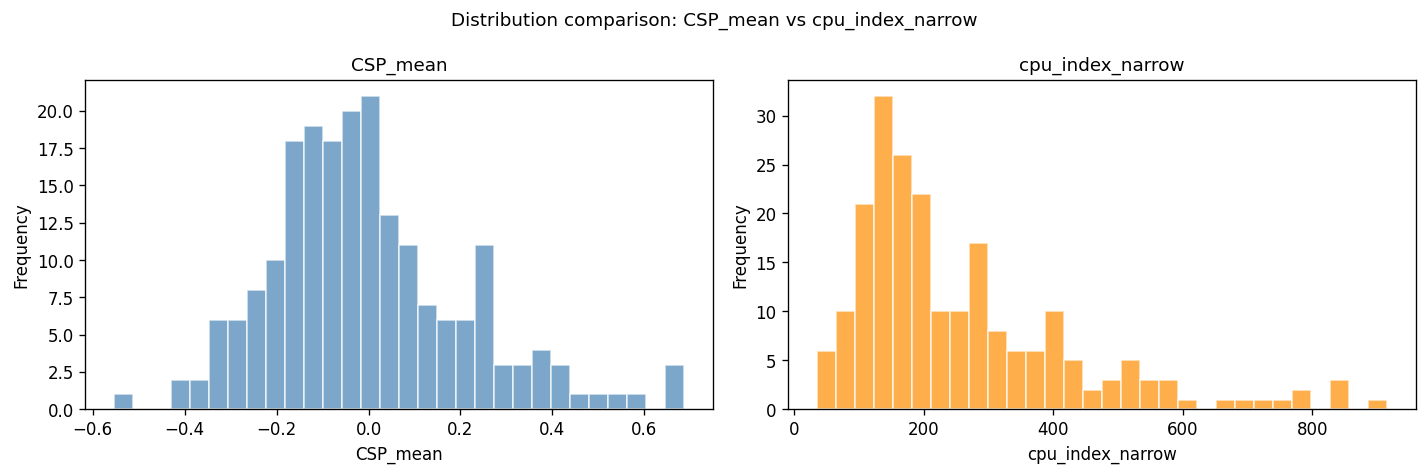

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(h_df["CSP_mean"].dropna(), bins=30,
             color="steelblue", alpha=0.7, edgecolor="white")
axes[0].set_title("CSP_mean", fontsize=11)
axes[0].set_xlabel("CSP_mean")
axes[0].set_ylabel("Frequency")

axes[1].hist(h_df["cpu_index_narrow"].dropna(), bins=30,
             color="darkorange", alpha=0.7, edgecolor="white")
axes[1].set_title("cpu_index_narrow", fontsize=11)
axes[1].set_xlabel("cpu_index_narrow")
axes[1].set_ylabel("Frequency")

fig.suptitle("Distribution comparison: CSP_mean vs cpu_index_narrow",
             fontsize=11)
fig.tight_layout()
fig.savefig(figdir / "h9_distribution_comparison.png", dpi=150)
plt.show()

### Time series comparison plot

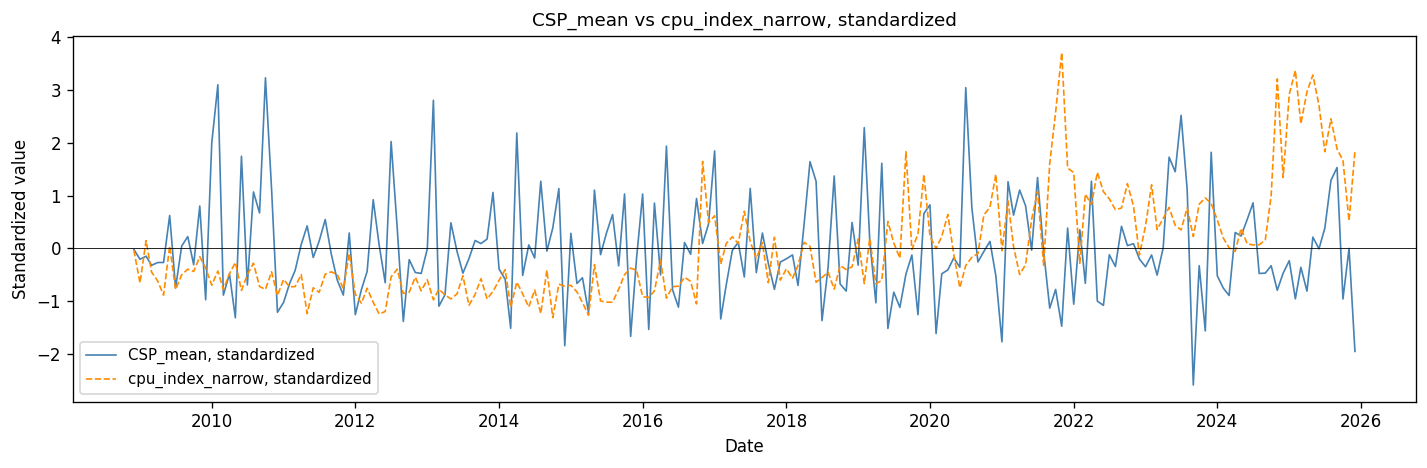

In [23]:
plot_df = h_df[["date", "CSP_mean", "cpu_index_narrow"]].dropna().copy()
plot_df["CSP_mean_z"]        = ((plot_df["CSP_mean"] - plot_df["CSP_mean"].mean())
                                 / plot_df["CSP_mean"].std())
plot_df["cpu_index_narrow_z"] = ((plot_df["cpu_index_narrow"] - plot_df["cpu_index_narrow"].mean())
                                  / plot_df["cpu_index_narrow"].std())

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(plot_df["date"], plot_df["CSP_mean_z"],
        label="CSP_mean, standardized", lw=1.0, color="steelblue")
ax.plot(plot_df["date"], plot_df["cpu_index_narrow_z"],
        label="cpu_index_narrow, standardized", lw=1.0,
        color="darkorange", linestyle="--")
ax.axhline(0, color="black", lw=0.5)
ax.set_title("CSP_mean vs cpu_index_narrow, standardized", fontsize=11)
ax.set_xlabel("Date")
ax.set_ylabel("Standardized value")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(figdir / "h4_csp_vs_cpu_timeseries.png", dpi=150)
plt.show()

### Scatter Plot

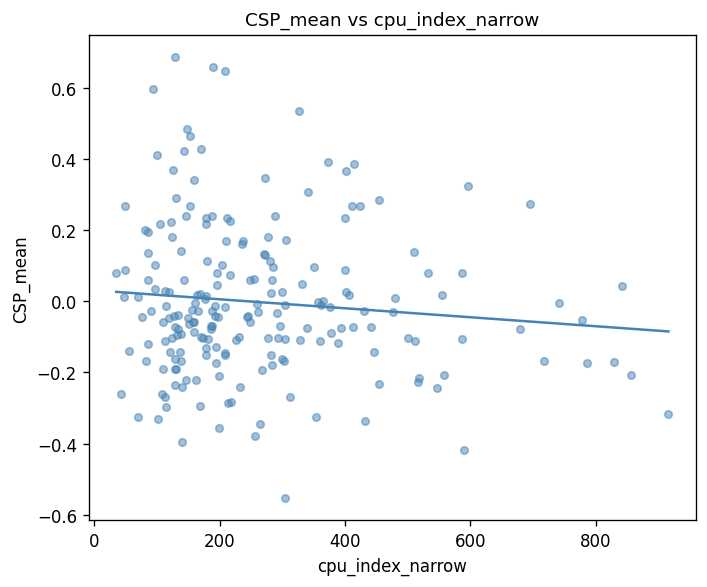

In [24]:
tmp_sc = h_df[["CSP_mean", "cpu_index_narrow"]].dropna()

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(tmp_sc["cpu_index_narrow"], tmp_sc["CSP_mean"],
           s=20, alpha=0.5, color="steelblue")
m, b = np.polyfit(tmp_sc["cpu_index_narrow"], tmp_sc["CSP_mean"], 1)
x_range = np.linspace(tmp_sc["cpu_index_narrow"].min(),
                      tmp_sc["cpu_index_narrow"].max(), 100)
ax.plot(x_range, m * x_range + b, color="steelblue", lw=1.5)
ax.set_xlabel("cpu_index_narrow")
ax.set_ylabel("CSP_mean")
ax.set_title("CSP_mean vs cpu_index_narrow", fontsize=11)
fig.tight_layout()
fig.savefig(figdir / "h5_csp_vs_cpu_scatter.png", dpi=150)
plt.show()

### Rolling Correlation

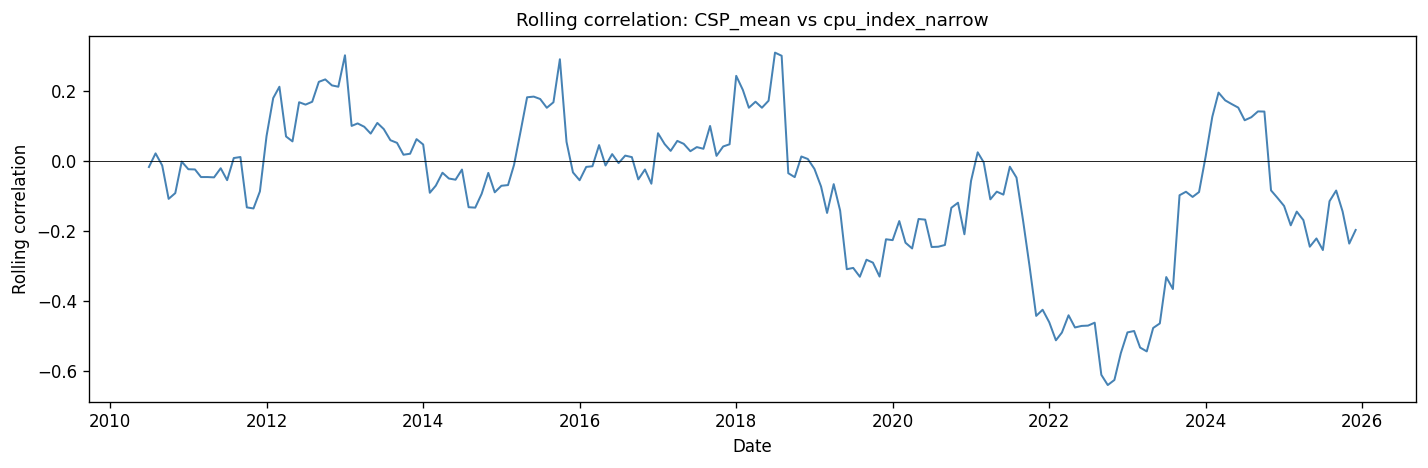

In [25]:
plot_df["rolling_corr"] = (plot_df["CSP_mean_z"]
    .rolling(20, min_periods=20)
    .corr(plot_df["cpu_index_narrow_z"]))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(plot_df["date"], plot_df["rolling_corr"],
        lw=1.2, color="steelblue")
ax.axhline(0, color="black", lw=0.5)
ax.set_title("Rolling correlation: CSP_mean vs cpu_index_narrow",
             fontsize=11)
ax.set_xlabel("Date")
ax.set_ylabel("Rolling correlation")
fig.tight_layout()
fig.savefig(figdir / "rolling_corr.png", dpi=150)
plt.show()

### Distribution Analysis

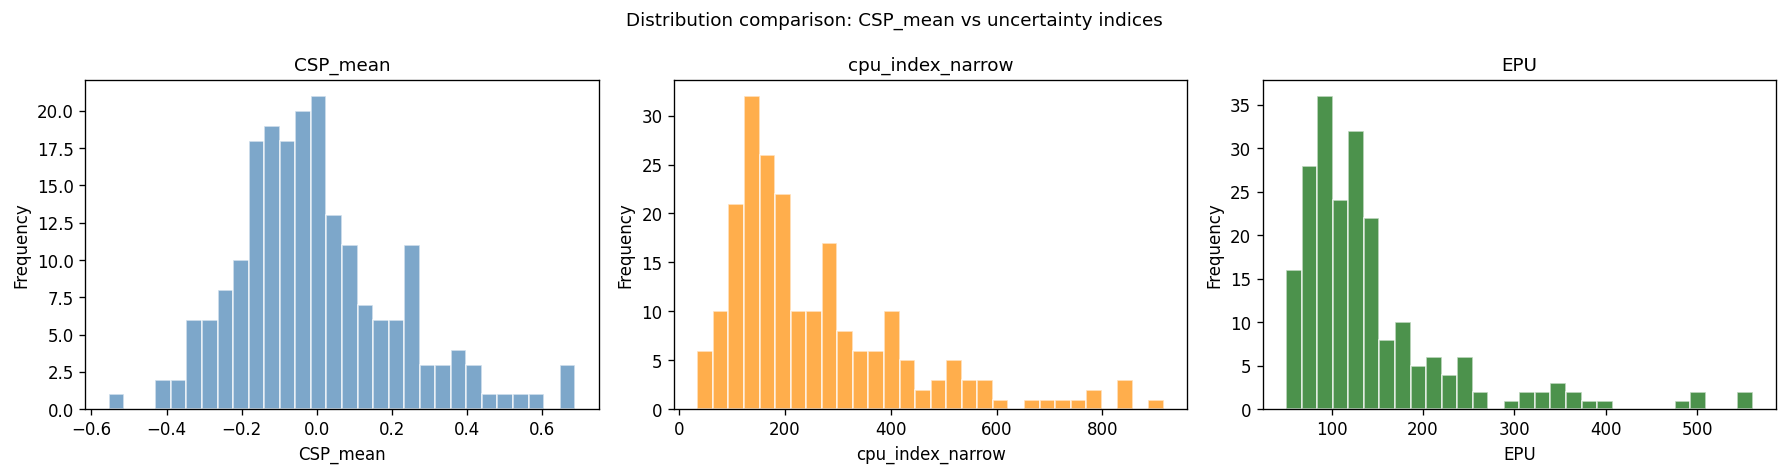

In [26]:
compare_cols = [c for c in ["cpu_index_narrow", "EPU", "gri"]
                if c in h_df.columns]
n_plots = 1 + len(compare_cols)

fig, axes = plt.subplots(1, n_plots, figsize=(5 * n_plots, 4))

axes[0].hist(h_df["CSP_mean"].dropna(), bins=30,
             color="steelblue", alpha=0.7, edgecolor="white")
axes[0].set_title("CSP_mean", fontsize=11)
axes[0].set_xlabel("CSP_mean")
axes[0].set_ylabel("Frequency")

colors = ["darkorange", "darkgreen", "firebrick"]
for i, col in enumerate(compare_cols):
    axes[i+1].hist(h_df[col].dropna(), bins=30,
                   color=colors[i], alpha=0.7, edgecolor="white")
    axes[i+1].set_title(col, fontsize=11)
    axes[i+1].set_xlabel(col)
    axes[i+1].set_ylabel("Frequency")

fig.suptitle("Distribution comparison: CSP_mean vs uncertainty indices",
             fontsize=11)
fig.tight_layout()
fig.savefig(figdir / "h9_distribution_comparison.png", dpi=150)
plt.show()

# PCA

## CSP vs CPU

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_cols = ["CSP_mean", "cpu_index_narrow"]
pca_df   = h_df[pca_cols].dropna()

print(f"PCA columns: {pca_cols}")
print(f"Complete PCA rows: {len(pca_df)}")
print(f"Number of PCA variables: {len(pca_cols)}")

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(pca_df)
pca      = PCA(n_components=len(pca_cols))
pca.fit(X_scaled)

var_df = pd.DataFrame(
    {"var_explained": pca.explained_variance_ratio_.round(3)},
    index=[f"PC{i+1}" for i in range(len(pca_cols))])
print("\nVariance explained per component:")
display(var_df)

PCA columns: ['CSP_mean', 'cpu_index_narrow']
Complete PCA rows: 205
Number of PCA variables: 2

Variance explained per component:


,var_explained
PC1,0.552000
PC2,0.448000


In [28]:
loadings_df = pd.DataFrame(
    pca.components_.T.round(3),
    index=pca_cols,
    columns=[f"PC{i+1}" for i in range(len(pca_cols))])
print("\nLoadings (rows = variables, columns = principal components):")
display(loadings_df)


Loadings (rows = variables, columns = principal components):


,PC1,PC2
CSP_mean,0.707000,0.707000
cpu_index_narrow,-0.707000,0.707000


## CSP vs EPU

In [29]:
pca_cols = ["CSP_mean", "EPU"]
pca_df   = h_df[pca_cols].dropna()

print(f"PCA columns: {pca_cols}")
print(f"Complete PCA rows: {len(pca_df)}")

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(pca_df)
pca      = PCA(n_components=len(pca_cols))
pca.fit(X_scaled)

var_df = pd.DataFrame(
    {"var_explained": pca.explained_variance_ratio_.round(3)},
    index=[f"PC{i+1}" for i in range(len(pca_cols))])
print("\nVariance explained per component:")
display(var_df)


PCA columns: ['CSP_mean', 'EPU']
Complete PCA rows: 205

Variance explained per component:


,var_explained
PC1,0.501000
PC2,0.499000


In [30]:
loadings_df = pd.DataFrame(
    pca.components_.T.round(3),
    index=pca_cols,
    columns=[f"PC{i+1}" for i in range(len(pca_cols))])
print("\nLoadings:")
display(loadings_df)


Loadings:


,PC1,PC2
CSP_mean,0.707000,0.707000
EPU,-0.707000,0.707000


## CSP vs CPU vs EPU

In [31]:
pca_cols = ["CSP_mean", "cpu_index_narrow", "EPU"]
pca_df   = h_df[pca_cols].dropna()

print(f"PCA columns: {pca_cols}")
print(f"Complete PCA rows: {len(pca_df)}")
print(f"Number of PCA variables: {len(pca_cols)}")

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(pca_df)
pca      = PCA(n_components=len(pca_cols))
pca.fit(X_scaled)

var_df = pd.DataFrame(
    {"var_explained": pca.explained_variance_ratio_.round(3)},
    index=[f"PC{i+1}" for i in range(len(pca_cols))])
print("\nVariance explained per component:")
display(var_df)


PCA columns: ['CSP_mean', 'cpu_index_narrow', 'EPU']
Complete PCA rows: 205
Number of PCA variables: 3

Variance explained per component:


,var_explained
PC1,0.509000
PC2,0.333000
PC3,0.158000


In [32]:

loadings_df = pd.DataFrame(
    pca.components_.T.round(3),
    index=pca_cols,
    columns=[f"PC{i+1}" for i in range(len(pca_cols))])
print("\nLoadings (rows = variables, columns = principal components):")
display(loadings_df)


Loadings (rows = variables, columns = principal components):


,PC1,PC2,PC3
CSP_mean,-0.143000,0.980000,0.137000
cpu_index_narrow,0.707000,0.005000,0.707000
EPU,0.693000,0.198000,-0.693000


## PCA visuals

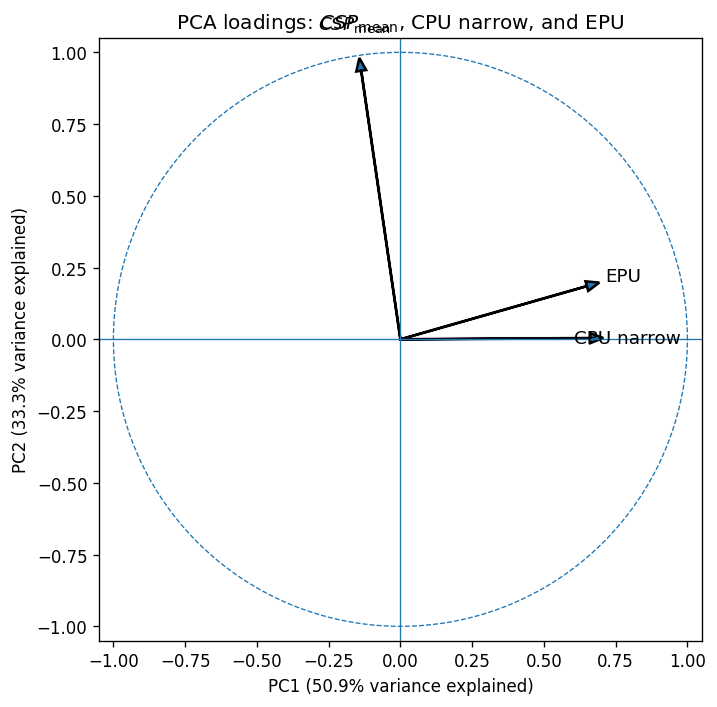

,PC1,PC2,PC3
CSP_mean,-0.143000,0.980000,0.137000
cpu_index_narrow,0.707000,0.005000,0.707000
EPU,0.693000,0.198000,-0.693000


,Variance explained
PC1,0.509000
PC2,0.333000
PC3,0.158000


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_cols = ["CSP_mean", "cpu_index_narrow", "EPU"]
pca_df = h_df[pca_cols].dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(pca_df)

pca = PCA(n_components=3)
pca.fit(X_scaled)

loadings_df = pd.DataFrame(
    pca.components_.T,
    index=pca_cols,
    columns=["PC1", "PC2", "PC3"]
)

var_explained = pca.explained_variance_ratio_

label_map = {
    "CSP_mean": r"$CSP_{\mathrm{mean}}$",
    "cpu_index_narrow": "CPU narrow",
    "EPU": "EPU"
}

fig, ax = plt.subplots(figsize=(7, 6))

for var in loadings_df.index:
    x = loadings_df.loc[var, "PC1"]
    y = loadings_df.loc[var, "PC2"]

    ax.arrow(
        0, 0, x, y,
        head_width=0.035,
        head_length=0.045,
        length_includes_head=True,
        linewidth=1.5
    )

    ax.text(
        x * 1.12,
        y * 1.12,
        label_map[var],
        ha="center",
        va="center",
        fontsize=11
    )

ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)

theta = np.linspace(0, 2 * np.pi, 300)
ax.plot(np.cos(theta), np.sin(theta), linestyle="--", linewidth=0.8)

ax.set_xlim(-1.05, 1.05)
ax.set_ylim(-1.05, 1.05)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(f"PC1 ({var_explained[0] * 100:.1f}% variance explained)")
ax.set_ylabel(f"PC2 ({var_explained[1] * 100:.1f}% variance explained)")
ax.set_title(r"PCA loadings: $CSP_{\mathrm{mean}}$, CPU narrow, and EPU")

plt.tight_layout()
plt.savefig(figdir / "pca_loadings_csp_cpu_epu.png", dpi=300, bbox_inches="tight")
plt.show()

display(loadings_df.round(3))
display(pd.DataFrame(
    {"Variance explained": var_explained.round(3)},
    index=["PC1", "PC2", "PC3"]
))



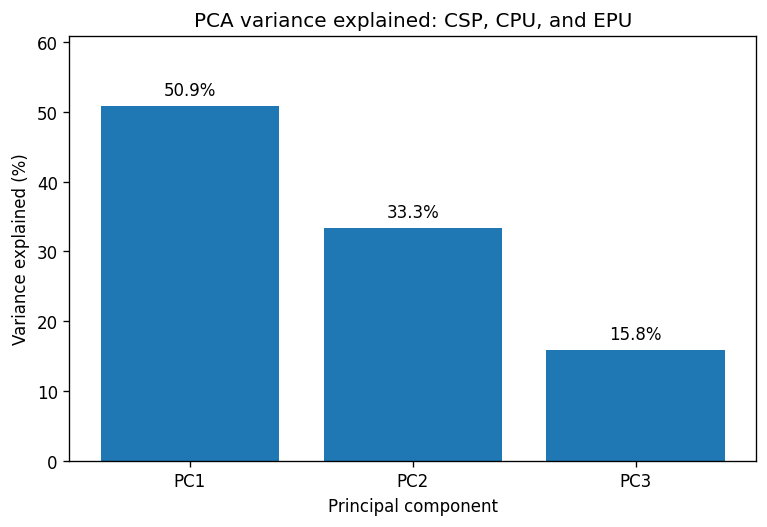

,Component,Variance explained
0,PC1,50.900000
1,PC2,33.300000
2,PC3,15.800000


In [34]:
# PCA visual: variance explained bar chart

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_cols = ["CSP_mean", "cpu_index_narrow", "EPU"]
pca_df = h_df[pca_cols].dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(pca_df)

pca = PCA(n_components=3)
pca.fit(X_scaled)

var_df = pd.DataFrame({
    "Component": ["PC1", "PC2", "PC3"],
    "Variance explained": pca.explained_variance_ratio_ * 100
})

fig, ax = plt.subplots(figsize=(6.5, 4.5))

ax.bar(
    var_df["Component"],
    var_df["Variance explained"]
)

ax.set_ylabel("Variance explained (%)")
ax.set_xlabel("Principal component")
ax.set_title("PCA variance explained: CSP, CPU, and EPU")

for i, value in enumerate(var_df["Variance explained"]):
    ax.text(
        i,
        value + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )

ax.set_ylim(0, max(var_df["Variance explained"]) + 10)

plt.tight_layout()
plt.savefig(figdir / "pca_variance_explained_bar.png", dpi=300, bbox_inches="tight")
plt.show()

display(var_df.round(1))



In [35]:
for name, obj in [("csp_monthly", csp_monthly), ("cpu_monthly", cpu_monthly)]:
    print(name, "| type:", type(obj).__name__,
          "| shape:", getattr(obj, "shape", None))
    if hasattr(obj, "columns"):
        print("   columns:", list(obj.columns))
    print("   index type:", type(obj.index).__name__, "| index name:", obj.index.name)
    print("   head:")
    print(obj.head(3))
    print()

csp_monthly | type: DataFrame | shape: (216, 6)
   columns: ['month', 'CSP_mean', 'CSP_std', 'CSP_max_abs', 'CSP_n', 'date']
   index type: RangeIndex | index name: None
   head:
     month  CSP_mean  CSP_std  CSP_max_abs  CSP_n       date
0  2008-01       NaN      NaN          NaN      0 2008-01-01
1  2008-02       NaN      NaN          NaN      0 2008-02-01
2  2008-03       NaN      NaN          NaN      0 2008-03-01

cpu_monthly | type: DataFrame | shape: (216, 9)
   columns: ['date', 'cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
   index type: RangeIndex | index name: None
   head:
        date  cpu_index_narrow  cpu_index_broad  cpu_index_gavriilidis  \
0 2008-01-01        165.633687       139.253340              94.648509   
1 2008-02-01        143.749401       122.719308              96.943516   
2 2008-03-01        111.876447        75.812874              55.128163   



In [36]:
from scipy.stats import fisher_exact
import pandas as pd, numpy as np


csp = csp_monthly[["date", "CSP_mean"]].copy()
cpu = cpu_monthly[["date", "cpu_index_narrow"]].copy()
csp["date"] = pd.to_datetime(csp["date"]).dt.to_period("M")
cpu["date"] = pd.to_datetime(cpu["date"]).dt.to_period("M")

m = csp.merge(cpu, on="date", how="inner", validate="1:1").dropna()
print(f"aligned months (after dropping NaN CSP): {len(m)}")

hi_csp = m["CSP_mean"]         >= m["CSP_mean"].quantile(0.75)
hi_cpu = m["cpu_index_narrow"] >= m["cpu_index_narrow"].quantile(0.75)

a = int(( hi_csp &  hi_cpu).sum())
b = int(( hi_csp & ~hi_cpu).sum())
c = int((~hi_csp &  hi_cpu).sum())
d = int((~hi_csp & ~hi_cpu).sum())

odds, p = fisher_exact([[a, b], [c, d]], alternative="two-sided")
N = a + b + c + d
print(f"high-CSP months    : {a + b}")
print(f"high-CPU months    : {a + c}")
print(f"overlap (both)     : {a}  ({100*a/(a+b):.1f}% of high-CSP)")
print(f"expected under indep: {(a+b)*(a+c)/N:.2f}")
print(f"Fisher exact p     : {p:.4f}")

aligned months (after dropping NaN CSP): 205
high-CSP months    : 52
high-CPU months    : 52
overlap (both)     : 11  (21.2% of high-CSP)
expected under indep: 13.19
Fisher exact p     : 0.4657


Merged monthly observations: 205


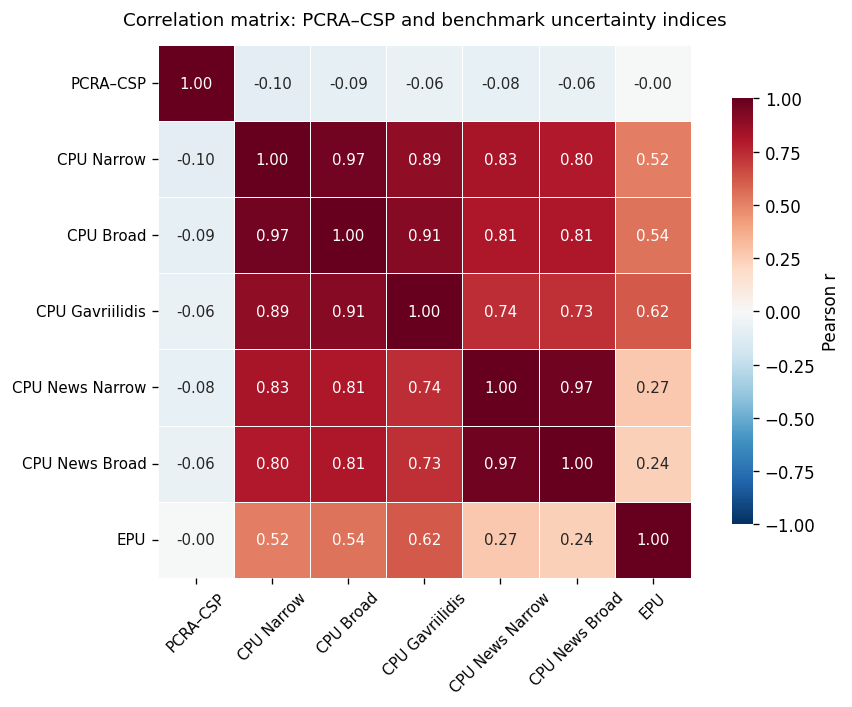

Saved to /Users/adam/Desktop/PCRA Index Thesis/Visuals/Discriminant Validity/correlation_heatmap_full.png


In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Builds monthly CSP_mean from daily DSP 
dsp_monthly = (
    df[['date', 'CSP']]
    .dropna(subset=['CSP'])
    .assign(month=lambda d: d['date'].dt.to_period('M'))
    .groupby('month')['CSP']
    .mean()
    .reset_index()
    .assign(date=lambda d: d['month'].dt.to_timestamp())
    [['date', 'CSP']]
    .rename(columns={'CSP': 'CSP_mean'})
)

#  Builds monthly EPU mean 
epu_monthly = (
    epu_df
    .assign(month=lambda d: d['date'].dt.to_period('M'))
    .groupby('month')['epu']
    .mean()
    .reset_index()
    .assign(date=lambda d: d['month'].dt.to_timestamp())
    [['date', 'epu']]
)

merged = (
    dsp_monthly
    .merge(cpu_df[['date', 'cpu_index_narrow', 'cpu_index_broad',
                   'cpu_index_gavriilidis', 'cpnews_index_narrow',
                   'cpnews_index_broad']], on='date', how='inner')
    .merge(epu_monthly, on='date', how='inner')
)

print(f"Merged monthly observations: {len(merged)}")

rename = {
    'CSP_mean':              'PCRA–CSP',
    'cpu_index_narrow':      'CPU Narrow',
    'cpu_index_broad':       'CPU Broad',
    'cpu_index_gavriilidis': 'CPU Gavriilidis',
    'cpnews_index_narrow':   'CPU News Narrow',
    'cpnews_index_broad':    'CPU News Broad',
    'epu':                   'EPU',
}

df_corr = merged[list(rename.keys())].rename(columns=rename)
corr = df_corr.corr(method='pearson')

# plot
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    linecolor='white',
    annot_kws={'size': 9},
    ax=ax,
    cbar_kws={'shrink': 0.8, 'label': 'Pearson r'}
)

ax.set_title('Correlation matrix: PCRA–CSP and benchmark uncertainty indices',
             fontsize=11, pad=12)
ax.tick_params(axis='x', rotation=45, labelsize=9)
ax.tick_params(axis='y', rotation=0, labelsize=9)

plt.tight_layout()
plt.savefig(figdir / "correlation_heatmap_full.png", dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved to {figdir / 'correlation_heatmap_full.png'}")

Merged monthly observations: 205


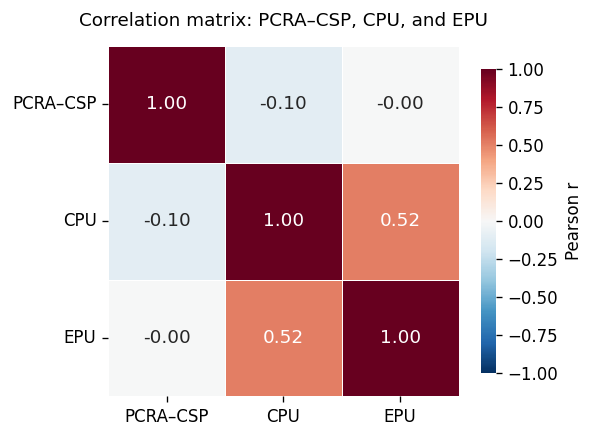

Saved to /Users/adam/Desktop/PCRA Index Thesis/Visuals/Discriminant Validity/correlation_heatmap_narrow.png


In [38]:
merged3 = (
    dsp_monthly
    .merge(cpu_df[['date', 'cpu_index_narrow']], on='date', how='inner')
    .merge(epu_monthly, on='date', how='inner')
)

print(f"Merged monthly observations: {len(merged3)}")

rename = {
    'CSP_mean':         'PCRA–CSP',
    'cpu_index_narrow': 'CPU',
    'epu':              'EPU',
}

df_corr = merged3[list(rename.keys())].rename(columns=rename)
corr = df_corr.corr(method='pearson')

# plot
fig, ax = plt.subplots(figsize=(5, 4))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    linecolor='white',
    annot_kws={'size': 11},
    ax=ax,
    cbar_kws={'shrink': 0.8, 'label': 'Pearson r'}
)

ax.set_title('Correlation matrix: PCRA–CSP, CPU, and EPU',
             fontsize=11, pad=12)
ax.tick_params(axis='x', rotation=0, labelsize=10)
ax.tick_params(axis='y', rotation=0, labelsize=10)

plt.tight_layout()
plt.savefig(figdir / "correlation_heatmap_narrow.png", dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved to {figdir / 'correlation_heatmap_narrow.png'}")